# Market Breadth Panels

**Family:** Finance & investment &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Finance & investment:* Performance, risk, portfolios, markets, rates, derivatives and valuation, the everyday charts of investors and analysts.

> ⚠️ Educational examples with simulated or historical data. Not investment advice; past performance does not predict future returns.

## Design purpose

Stacks a cap-weighted index above two breadth measures, the cumulative advance-decline line and the share of stocks above their 200-day moving average, on a shared time axis. It shows whether a rally is broad-based or carried by a few large companies.

## When to use

- Check if an index move reflects most stocks or a handful of mega-caps
- Spot divergences, such as an index making new highs while breadth weakens
- Use as market-health context in investment commentary

## Avoid when

- Overlaying the measures on one chart with two or three y-axes (scales are arbitrary and imply false crossovers)
- The audience needs a single headline number (show % of stocks above the 200-day MA as a stat)

## Alternatives

- Equal-weight vs cap-weight index (indexed to 100)
- Histogram of constituent returns

## Design tips

- Share the x-axis and align panels so the same date lines up vertically
- Shade the period of interest across all panels
- Give each panel its own title or y-label and its own natural scale
- Add a reference line (50%) to percentage breadth measures

## Example

300 simulated stocks over three years. In the last nine months the 12 largest rally while most others drift lower, which is a classic 'narrow market' (illustrative).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(12)
n_stocks, n_days, warm, late_days = 300, 950, 200, 190
cap0 = rng.lognormal(3, 1.2, n_stocks)                 # starting market caps
mega = np.zeros(n_stocks, bool)
mega[np.argsort(-cap0)[:12]] = True
market = rng.normal(0.0004, 0.009, n_days)
beta = rng.uniform(0.7, 1.3, n_stocks)
rets = market[:, None] * beta + rng.normal(0, 0.016, (n_days, n_stocks))
rets[-late_days:, ~mega] -= 0.0008                     # most stocks drift lower...
rets[-late_days:, mega] += 0.0024                      # ...while the giants rally
prices = pd.DataFrame(np.exp(np.cumsum(rets, axis=0)), index=pd.bdate_range("2022-01-03", periods=n_days))

cap_index = (prices * cap0).sum(axis=1)
daily = prices.pct_change()
ad_line = ((daily > 0).sum(axis=1) - (daily < 0).sum(axis=1)).cumsum()
pct_above = (prices > prices.rolling(200).mean()).mean(axis=1) * 100
df = pd.DataFrame({"index": cap_index, "ad_line": ad_line, "pct_above_200d": pct_above}).iloc[warm:]
df["index"] = 4000 * df["index"] / df["index"].iloc[0]
df["ad_line"] -= df["ad_line"].iloc[0]
narrow_start = df.index[-late_days]
df.tail()

,index,ad_line,pct_above_200d
2025-08-18,7115.670064,3808,36.000000
2025-08-19,7093.103130,3720,35.666667
2025-08-20,7058.124707,3588,33.666667
2025-08-21,7032.162337,3520,34.000000
2025-08-22,7129.238269,3720,38.000000


### Plot

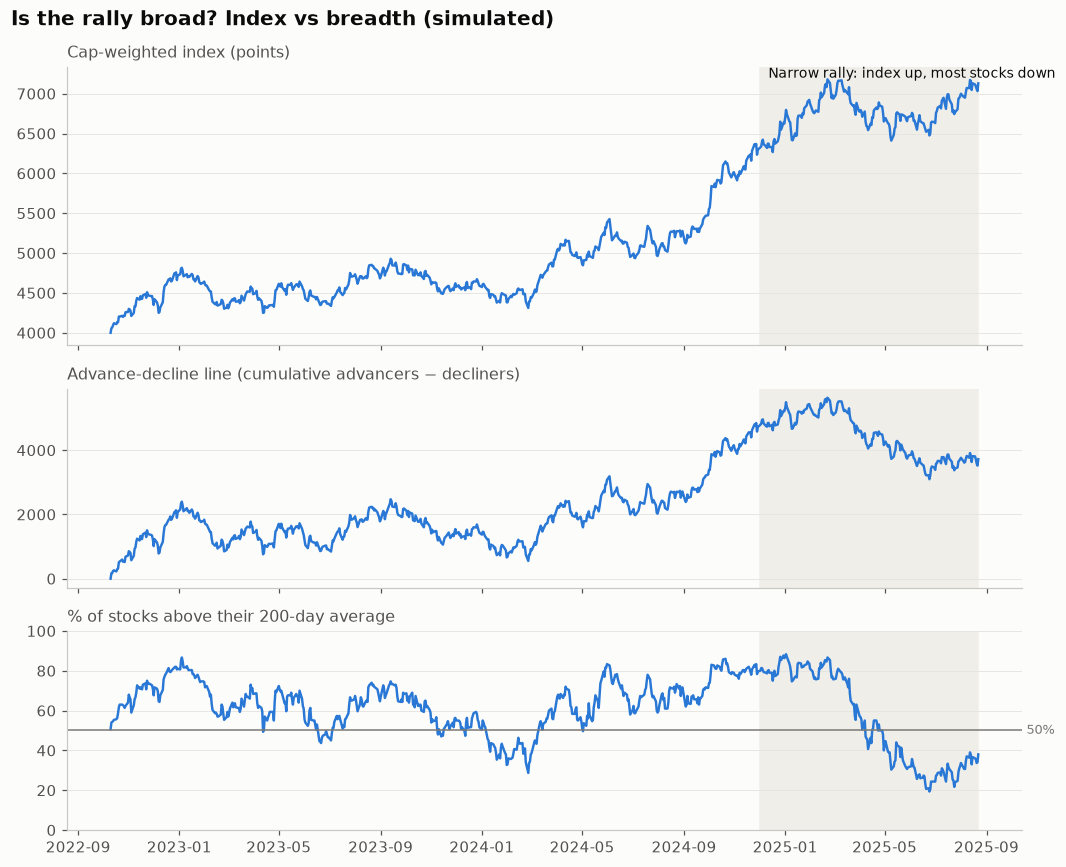

In [3]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True,
                         gridspec_kw={"height_ratios": [1.4, 1, 1]})
specs = [("index", "Cap-weighted index (points)"),
         ("ad_line", "Advance-decline line (cumulative advancers − decliners)"),
         ("pct_above_200d", "% of stocks above their 200-day average")]
for ax, (col, label) in zip(axes, specs):
    ax.axvspan(narrow_start, df.index[-1], color="#efeee9", zorder=0)
    ax.plot(df.index, df[col], color=PALETTE[0], linewidth=1.6)
    ax.set_title(label, fontsize=10.5, fontweight="normal", color="#52514e")
    ax.grid(axis="x", visible=False)
axes[2].axhline(50, color="#7a7974", linewidth=1)
axes[2].text(1.005, 50, "50%", transform=axes[2].get_yaxis_transform(), color="#7a7974",
             fontsize=8.5, va="center")
axes[2].set_ylim(0, 100)
axes[0].text(narrow_start, axes[0].get_ylim()[1], "  Narrow rally: index up, most stocks down",
             va="top", fontsize=9, color="#0b0b0b")
fig.suptitle("Is the rally broad? Index vs breadth (simulated)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout()
plt.show()

## How to read it

Inside the shaded period the index keeps rising, but the advance-decline line falls and fewer than half of stocks stay above their 200-day average. The gains come from a few heavyweights.

---
Standalone script: [`market_breadth.py`](market_breadth.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)